In [1]:
import glob
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import os
import json
import time
import pandas as pd
import seaborn as sns
import pickle
import matplotlib.patches as mpatches
import scipy.stats as stats
import csv

In [6]:
font = {"family" : "normal",
    "size" : 18}

for key, value in font.items():
    plt.rcParams.update({"font." + key : value})

chiral_ls = "dashed"
achiral_ls = "dotted"

chnops_color = "dimgrey"
kegg_color = "darkgrey"

color_number = {"LUCA":"#10D410", "Archaea":"#D65E00", "Bacteria":"#0B77B5", 
                "Eukarya":"#E69F03", "Metagenome":"#009E73", "Biosphere": "#4B0092"} 

In [3]:
import numpy as np
from scipy.optimize import curve_fit
from scipy import stats


def linlaw(x, a, b) :
    return a * x + b

def powerlaw(x, a, b, c):
    return b*x**a + c

def curve_fit_log_linear(xdata, ydata) :
    xdata_log = np.log10(xdata)
    # Fit linear
    popt_log, pcov_log = curve_fit(linlaw, xdata_log, ydata)
    # y variables as results from fitting
    ydatafit = linlaw(xdata_log, *popt_log)
    return (popt_log, pcov_log, ydatafit)

def curve_fit_log_log(xdata, ydata) :
    
    xdata_log = np.log10(xdata)
    ydata_log = np.log10(ydata)
    # Fit linear
    popt_log, pcov_log = curve_fit(linlaw, xdata_log, ydata_log)
    # y variables as results from fitting
    ydatafit = pow(10, linlaw(xdata_log, *popt_log))
    return (popt_log, pcov_log, ydatafit)

def find_fit(X,Y,color):
    slope, intercept, r_value, p_value, std_err = stats.linregress(X,Y)
    print('Slope: {:.6f}'.format(slope),'Intercept: {:.6f}'.format(intercept),'R-squared: {:.6f}'.format(r_value**2),'Std_err: {:.6f}'.format(std_err))
    x_dummy = np.linspace(start=0, stop=8000, num=100)
    plt.plot(x_dummy,slope*x_dummy + intercept,color=color)
    plt.fill_between(x_dummy,slope*x_dummy+intercept-std_err,slope*x_dummy+intercept+std_err,color=color, alpha=0.2)


def find_powerlaw_fit(x,y,color):
    if x == 0:
        x = 0.000001
    if y == 0:
        y = 0.000001
    X = np.log10(x)
    Y = np.log10(y)

    slope, intercept, r_value, p_value, std_err = stats.linregress(X,Y)
    print('Slope: {:.6f}'.format(slope),'Intercept: {:.6f}'.format(intercept),'R-squared: {:.6f}'.format(r_value**2),'Std_err: {:.6f}'.format(std_err))
    x_dummy = np.linspace(start=-500, stop=8000, num=100)
    plt.plot(x_dummy,(10**intercept)*(x_dummy**slope) ,color=color)


In [4]:
data_dir = "Data/"
df = dict()
for domain in ["Archaea", "Metagenome", "Bacteria", "Eukarya", "Biosphere", "LUCA"]:
    df[domain] = pd.read_csv(data_dir + "species_chirality_in_%s.csv"%domain)

## Reaxys Data

chnops = pickle.load(file=open("Data/chiral_chnops_sampling_FULL.p", "rb"))
kegg = pickle.load(file=open("Data/chiral_kegg_sampling_FULL.p", "rb"))

mws = np.arange(100,7100,100)

chnops_avgs = []
for s in chnops:
    chnops_avgs.append(np.mean(s))

kegg_avgs = []
for s in kegg:
    kegg_avgs.append(np.mean(s))

Slope: 0.000009 Intercept: 0.572096 R-squared: 0.097244 Std_err: 0.000000
Slope: -0.000074 Intercept: 0.708940 R-squared: 0.494065 Std_err: 0.000001
Slope: -0.000106 Intercept: 0.739776 R-squared: 0.346741 Std_err: 0.000004
Slope: -0.000027 Intercept: 0.653523 R-squared: 0.200469 Std_err: 0.000003
Slope: 0.000000 Intercept: 0.566413 R-squared: 0.007606 Std_err: 0.000000
Slope: -0.000000 Intercept: 0.541487 R-squared: 0.016359 Std_err: 0.000000
Biosphere ratio: 0    0.632304
Name: ratio_chiral, dtype: float64
LUCA ratio: 0    0.652968
Name: ratio_chiral, dtype: float64


/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/ipykernel_launcher.py:62: UserWarning: The handle <matplotlib.collections.PathCollection object at 0x7f9e20862610> has a label of '_child20' which cannot be automatically added to the legend.
/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/ipykernel_launcher.py:62: UserWarning: The handle <matplotlib.collections.PathCollection object at 0x7f9e20862150> has a label of '_child23' which cannot be automatically added to the legend.
/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/ipykernel_launcher.py:118: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.


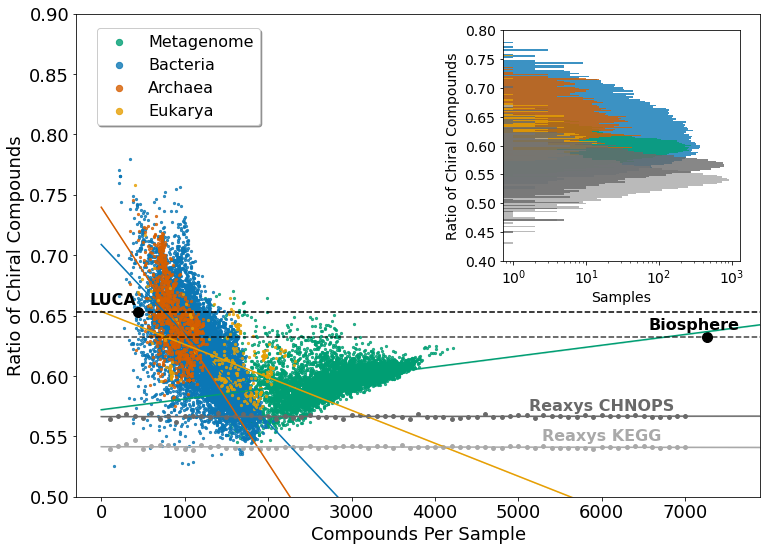

In [7]:
""" Manuscript chiral figure

Combining distribution & scatter plots, arranging axes correctly, removing some of legend for ease of readability

"""

fig, ax = plt.subplots(figsize=(11, 8))

list_domain = ["Metagenome", "Bacteria", "Archaea", "Eukarya"]

handles = [] #Handle array used for legend compatibility with Reaxys sampling

for domain in list_domain:
    x = df[domain].total_size
    y = df[domain].ratio_chiral
    s = ax.scatter(x, y, label = domain, s=5, color=color_number[domain], alpha=0.8)
    handles.append(s) #Adding lines to an array for legend labeling
    find_fit(x, y, color_number[domain])

# Add Reaxys averages to scatter plot
ax.scatter(mws, chnops_avgs, color=chnops_color, s=15)
ax.annotate("Reaxys CHNOPS", (6000, 0.575), color=chnops_color, weight='bold', 
            fontsize=16, ha='center', va='center')

ax.scatter(mws, kegg_avgs, color=kegg_color, s=15)
ax.annotate("Reaxys KEGG", (6000, 0.55), color=kegg_color, weight='bold', 
            fontsize=16, ha='center', va='center')

# Add scaling fits (fit a polyfit line to averages)
find_fit(mws, chnops_avgs, chnops_color)
find_fit(mws, kegg_avgs, kegg_color)

#Add Reaxys to Legend
chnops_patch = plt.Line2D([], [], color=chnops_color, marker="o", linewidth=0, label='Reaxys: CHNOPS Elements')
kegg_patch = plt.Line2D([], [], color=kegg_color, marker="o", linewidth=0, label='Reaxys: KEGG Elements')


# Line for biosphere
x = df["Biosphere"].total_size
y = df["Biosphere"].ratio_chiral
print("Biosphere ratio:", y)
s = ax.scatter(x, y, s=100, color="k") #, label="Biosphere")
ax.annotate("Biosphere", (x - 150, y + 0.01), color="k", weight='bold', 
            fontsize=16, ha='center', va='center')
handles.append(s)
plt.plot([-500, 8000], [y, y], ls='--', color="k", alpha=0.75)

# Line for Luca
x = df["LUCA"].total_size
y = df["LUCA"].ratio_chiral
print("LUCA ratio:", y)
s = ax.scatter(x, y, s=100, color="k") #, label="LUCA")
ax.annotate("LUCA", (x - 300, y + 0.01), color="k", weight='bold', 
            fontsize=16, ha='center', va='center')
handles.append(s)
plt.plot([-500, 8000], [y, y], ls='--', color="k", alpha=1)

## Add Reaxys patches to handles
# handles.extend([chnops_patch, kegg_patch])

# Legend
lgnd = ax.legend(handles = handles, bbox_to_anchor=(0.03, 0.97), loc=2, borderaxespad=0., shadow=True, prop={"size": 16})

for n in range(len(list_domain)):
    lgnd.legendHandles[n]._sizes = [40]

# Labels
font_size = 14
ax.set_xlabel("Compounds Per Sample")
ax.set_ylabel("Ratio of Chiral Compounds")

# Axis
ax.set_ylim(0.50,0.90)
ax.set_xlim(-300, 7900)

### Inset distribution axes
left, bottom, width, height = [0.65, 0.525, 0.3, 0.4]
ax2 = fig.add_axes([left, bottom, width, height])

list_domain = ["Bacteria", "Metagenome",  "Archaea", "Eukarya"]

for domain in list_domain:
    x = df[domain].total_size
    y = df[domain].ratio_chiral
    num_bins = 100
    n, bins, patches = plt.hist(y, num_bins, label=domain, facecolor=color_number[domain], alpha=0.8, orientation="horizontal")

#JM: flattening & adding Reaxys samples
num_bins = 100
ax2.hist([x for sub in kegg for x in sub], num_bins, label="Reaxys:\nKEGG Elements", facecolor=kegg_color, alpha=0.8, orientation="horizontal")
ax2.hist([x for sub in chnops for x in sub], num_bins, label="Reaxys:\nCHNOPS Elements", facecolor=chnops_color, alpha=0.8, orientation="horizontal")


# Line for biosphere
x = df["Biosphere"].total_size
y = df["Biosphere"].ratio_chiral
# ax2.plot([x, x], [-10, 1300], label = "Biosphere", ls='--', color="k", alpha=1)
# ax2.annotate("Biosphere", (y - 0.05, 1450), color="k", weight='bold', 
#             fontsize=18, ha='center', va='center')

# Line for Luca
x = df["LUCA"].total_size
y = df["LUCA"].ratio_chiral
# ax2.plot([x, x], [-10, 1300], label = "LUCA", ls='--', color="k", alpha=1)
# ax2.annotate("LUCA", (y + 0.03, 1450), color="k", weight='bold', 
#             fontsize=18, ha='center', va='center')

# Labels
font_size = 14
ax2.set_ylabel("Ratio of Chiral Compounds", fontsize=font_size)
ax2.set_xlabel("Samples", fontsize=font_size)

ax2.set_xscale('log')
ax2.tick_params(axis="both", which="major", labelsize=font_size)
ax2.set_ylim(0.4, 0.8)

# Layout
plt.tight_layout()

# Save Figure
# file_plot = "../../Figures/Fig2.svg"
# plt.savefig(file_plot)


In [8]:
# (maybe eventually will be an inset) Difference between chiral/achiral at each rank-order percentile

def get_chiral_difference(chiral_values, achiral_values, c, l, ax):

    #Step 1: get rank-order percentile values
    m_chiral_percentiles = []
    for i in np.linspace(0, len(chiral_values)-1, 100):
        m_chiral_percentiles.append(chiral_values[int(i)])

    m_achiral_percentiles = []
    for i in np.linspace(0, len(achiral_values)-1, 100):
        m_achiral_percentiles.append(achiral_values[int(i)])

    #Step 2: find difference
    m_diffs = list(np.array(m_chiral_percentiles) - np.array(m_achiral_percentiles))

    #Step 3: plot
    label = ax.plot(m_diffs, color=c, linewidth=3, label=l)

    return label

def make_AUC_dashes(u, label, c, ls, ax):
  yvals = list(u.values())
  xvals = np.linspace(0, 1, num=len(yvals))

  #Calculate AUC using composite travezoidal rule
  area = np.trapz(yvals, dx=xvals[1])
  # #AUC using Simpson's rule
  # area = simps(yvals, dx=xvals[1])
  # print(label, "Simpson's area:", area)

  ax.plot(xvals, yvals, label = label, color=c, 
    linestyle=ls, linewidth=4)
  
  print(label + " AUC = " + str(round(area, 4)))
  
  return yvals

#Separate domains into chiral vs achiral
#df is the chiral dataframe (columns=['Index', 'C', 'Smiles', 'Chiral_Centers'])
def find_chiral(u, df):
  achiral = {}
  chiral = {}

  for index, row in df.iterrows():
    if row["C"] in u:
      if row["Chiral_Centers"] > 0:
        chiral[row["C"]] = u[row["C"]]
      else:
        achiral[row["C"]] = u[row["C"]]

  return chiral, achiral
  

In [9]:
fp = "Data/chiral_molweight_formula_labels.csv"
kegg_df = pd.read_csv(fp)
kegg_df.head()

,C,S,Chiral_Centers,Mol_Weight,Formula
0,C00001,NaN,0,18.0153,H2O
1,C00002,Nc1ncnc2c1ncn2[C@@H]1O[C@H](COP(=O)(O)OP(=O)(O...,4,507.1810,C10H16N5O13P3
2,C00003,NC(=O)c1ccc[n+]([C@@H]2O[C@H](COP(=O)(O)OP(=O)...,8,664.4330,C21H28N7O14P2
3,C00004,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...,8,665.4410,C21H29N7O14P2
4,C00005,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...,8,745.4209,C21H30N7O17P3


In [10]:
#Read in occurence data & create universality percentages

num_bacteria = 10434
num_archaea = 1194
num_eukarya = 267
num_metagenomes = 6112

with open("Data/archaea_occurance.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  a_cpd_occurances = dict(reader)

with open("Data/bacteria_occurance.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  b_cpd_occurances = dict(reader)

with open("Data/eukarya_occurance.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  e_cpd_occurances = dict(reader)

with open("Data/metagenome_occurance.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  m_cpd_occurances = dict(reader)

#Translate occurances into % universality
a_cpd_universality = {}
b_cpd_universality = {}
e_cpd_universality = {}
m_cpd_universality = {}

#Num archaea: 1194
for item in a_cpd_occurances.items():
  a_cpd_universality[item[0]] = float(item[1]) / num_archaea

#num bacteria = 10434
for item in b_cpd_occurances.items():
  b_cpd_universality[item[0]] = float(item[1]) / num_bacteria

#Num eukarya: 267
for item in e_cpd_occurances.items():
  e_cpd_universality[item[0]] = float(item[1]) / num_eukarya

#Num metagenomes = 6112
for item in m_cpd_occurances.items():
  m_cpd_universality[item[0]] = float(item[1]) / num_metagenomes

In [11]:
#Find unversalities, and rank-order each
a_chiral_universality, a_achiral_universality = find_chiral(a_cpd_universality, kegg_df)
a_chiral_universality = {k: v for k, v in sorted(a_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
a_achiral_universality = {k: v for k, v in sorted(a_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

b_chiral_universality, b_achiral_universality = find_chiral(b_cpd_universality, kegg_df)
b_chiral_universality = {k: v for k, v in sorted(b_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
b_achiral_universality = {k: v for k, v in sorted(b_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

e_chiral_universality, e_achiral_universality = find_chiral(e_cpd_universality, kegg_df)
e_chiral_universality = {k: v for k, v in sorted(e_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
e_achiral_universality = {k: v for k, v in sorted(e_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

m_chiral_universality, m_achiral_universality = find_chiral(m_cpd_universality, kegg_df)
m_chiral_universality = {k: v for k, v in sorted(m_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
m_achiral_universality = {k: v for k, v in sorted(m_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/ipykernel_launcher.py:44: UserWarning: FixedFormatter should only be used together with FixedLocator
/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/ipykernel_launcher.py:45: UserWarning: FixedFormatter should only be used together with FixedLocator
findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.


Metagenome, Chiral AUC = 0.575
Metagenome, Achiral AUC = 0.6652
Eukarya, Chiral AUC = 0.395
Eukarya, Achiral AUC = 0.4196
Bacteria, Chiral AUC = 0.3341
Bacteria, Achiral AUC = 0.3201
Archaea, Chiral AUC = 0.34
Archaea, Achiral AUC = 0.2647


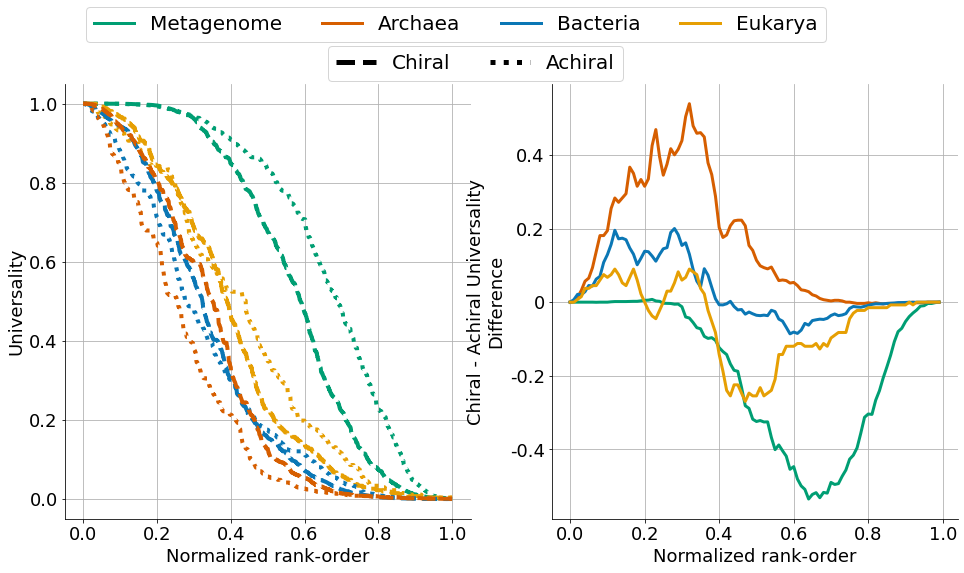

In [12]:
#All three domains together
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16,8)) 

m_chiral = make_AUC_dashes(m_chiral_universality, "Metagenome, Chiral", color_number["Metagenome"], chiral_ls, ax1)
m_achiral = make_AUC_dashes(m_achiral_universality, "Metagenome, Achiral", color_number["Metagenome"], achiral_ls, ax1)

e_chiral = make_AUC_dashes(e_chiral_universality, "Eukarya, Chiral", color_number["Eukarya"], chiral_ls, ax1)
e_achiral = make_AUC_dashes(e_achiral_universality, "Eukarya, Achiral", color_number["Eukarya"], achiral_ls, ax1)

b_chiral = make_AUC_dashes(b_chiral_universality, "Bacteria, Chiral", color_number["Bacteria"], chiral_ls, ax1)
b_achiral = make_AUC_dashes(b_achiral_universality, "Bacteria, Achiral", color_number["Bacteria"], achiral_ls, ax1)

a_chiral = make_AUC_dashes(a_chiral_universality, "Archaea, Chiral", color_number["Archaea"], chiral_ls, ax1)
a_achiral = make_AUC_dashes(a_achiral_universality, "Archaea, Achiral", color_number["Archaea"], achiral_ls, ax1)

ax1.grid()
ax1.set_ylabel("Universality")
ax1.set_xlabel("Normalized rank-order")

# ax1.legend(prop={"size":14}, bbox_to_anchor=(0.65, 1))
#Legend
handles = []

chiral_patch = plt.Line2D([], [], color="k", linestyle="--", linewidth=5, label='Chiral')
achiral_patch = plt.Line2D([], [], color="k", linestyle=":", linewidth=5, label='Achiral')

## Add Reaxys patches to handles
handles.extend([chiral_patch, achiral_patch])
ax1.legend(bbox_to_anchor=(1.4, 1.11), handles = handles, ncol = 2, prop={"size": 20})

# Hide the right and top spines
ax1.spines[['right', 'top']].set_visible(False)


### Inset 
get_chiral_difference(m_chiral, m_achiral, color_number["Metagenome"], "Metagenome", ax2)
get_chiral_difference(a_chiral, a_achiral, color_number["Archaea"], "Archaea", ax2)
get_chiral_difference(b_chiral, b_achiral, color_number["Bacteria"], "Bacteria", ax2)
get_chiral_difference(e_chiral, e_achiral, color_number["Eukarya"], "Eukarya", ax2)

ax2.grid()
ax2.legend(bbox_to_anchor=(0.7, 1.2), prop={"size":20}, ncol=4)

ax2.set_xticklabels([-0.2, 0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax2.set_yticklabels([-0.6, -0.4, -0.2, 0, 0.2, 0.4])
ax2.set_ylabel("Chiral - Achiral Universality\nDifference")
ax2.set_xlabel("Normalized rank-order")

ax2.spines[['right', 'top']].set_visible(False)

# file_plot = "../../Figures/Fig4.svg"
# plt.savefig(file_plot)
# # plt.tight_layout()


## Full Figure

Slope: 0.000009 Intercept: 0.572096 R-squared: 0.097244 Std_err: 0.000000
Slope: -0.000074 Intercept: 0.708940 R-squared: 0.494065 Std_err: 0.000001
Slope: -0.000106 Intercept: 0.739776 R-squared: 0.346741 Std_err: 0.000004
Slope: -0.000027 Intercept: 0.653523 R-squared: 0.200469 Std_err: 0.000003
Slope: 0.000000 Intercept: 0.566413 R-squared: 0.007606 Std_err: 0.000000
Slope: -0.000000 Intercept: 0.541487 R-squared: 0.016359 Std_err: 0.000000
Biosphere ratio: [0.6323043]
LUCA ratio: [0.65296804]
Metagenome, Chiral AUC = 0.575
Metagenome, Achiral AUC = 0.6652
Eukarya, Chiral AUC = 0.395
Eukarya, Achiral AUC = 0.4196
Bacteria, Chiral AUC = 0.3341
Bacteria, Achiral AUC = 0.3201
Archaea, Chiral AUC = 0.34
Archaea, Achiral AUC = 0.2647


/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/ipykernel_launcher.py:150: UserWarning: FixedFormatter should only be used together with FixedLocator
/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/ipykernel_launcher.py:151: UserWarning: FixedFormatter should only be used together with FixedLocator
/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/ipykernel_launcher.py:157: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations


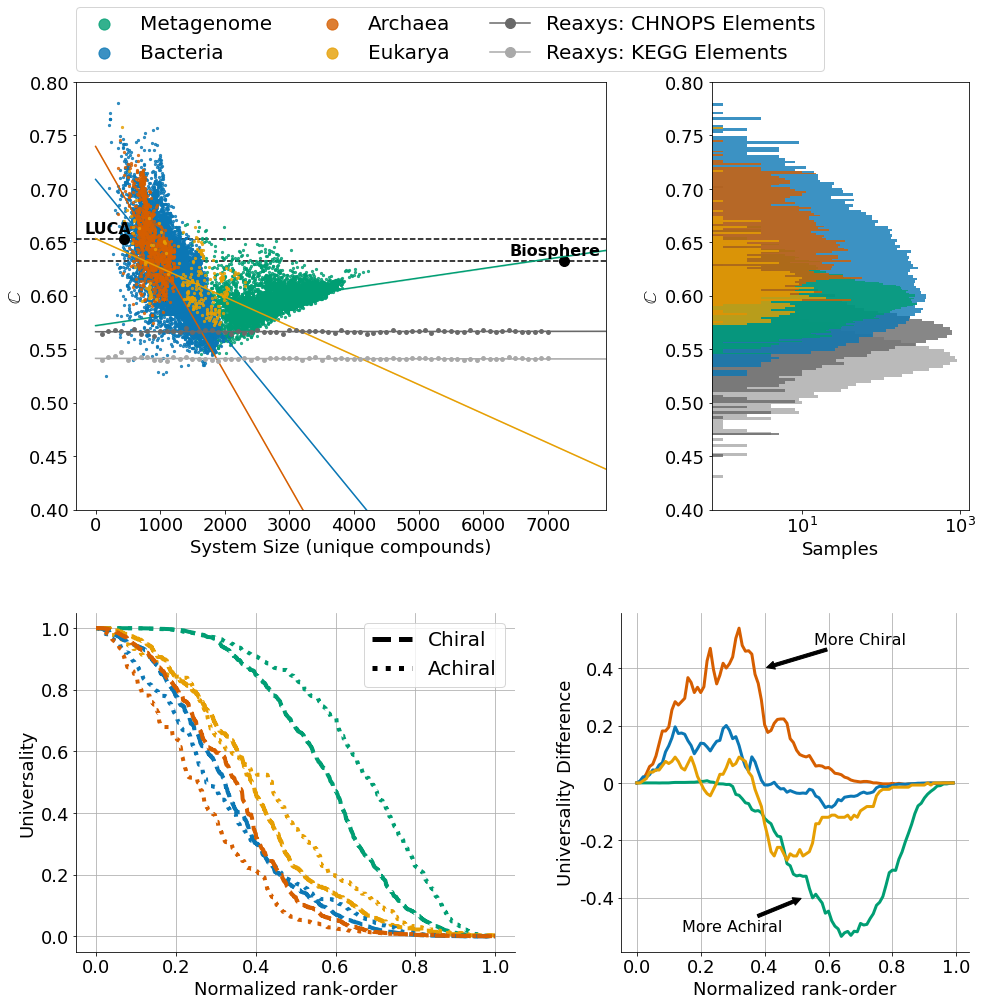

In [28]:
import matplotlib.gridspec as gridspec

plt.figure(figsize=(16,16))
gs = gridspec.GridSpec(10,10)
num_bins = 100

ax1 = plt.subplot(gs[0:5,0:6])

list_domain = ["Metagenome", "Bacteria", "Archaea", "Eukarya"]

handles = [] #Handle array used for legend compatibility with Reaxys sampling

for domain in list_domain:
    x = df[domain].total_size
    y = df[domain].ratio_chiral
    s = ax1.scatter(x, y, label = domain, s=5, color=color_number[domain], alpha=0.8, zorder=2)
    handles.append(s) #Adding lines to an array for legend labeling
    find_fit(x, y, color_number[domain])

# Add Reaxys averages to scatter plot
ax1.scatter(mws, chnops_avgs, color=chnops_color, s=15, zorder=2)
# ax1.annotate("Reaxys CHNOPS", (6000, 0.575), color=chnops_color, weight='bold', 
#             fontsize=16, ha='center', va='center')

ax1.scatter(mws, kegg_avgs, color=kegg_color, s=15, zorder=2)
# ax1.annotate("Reaxys KEGG", (6000, 0.55), color=kegg_color, weight='bold', 
#             fontsize=16, ha='center', va='center')

# Add scaling fits (fit a polyfit line to averages)
find_fit(mws, chnops_avgs, chnops_color)
find_fit(mws, kegg_avgs, kegg_color)

# Line for biosphere
x = df["Biosphere"].total_size
chiral_y = df["Biosphere"].ratio_chiral.values
print("Biosphere ratio:", chiral_y)
s = ax1.scatter(x, chiral_y, s=100, color="k") #, label="Biosphere")
ax1.annotate("Biosphere", (x - 150, chiral_y + 0.01), color="k", weight='bold', 
            fontsize=16, ha='center', va='center')
#handles.append(s)
ax1.axhline(chiral_y, 0, 1, ls='--', color="k", alpha=1, zorder=1)

# Line for Luca
x = df["LUCA"].total_size
chiral_y = df["LUCA"].ratio_chiral.values
print("LUCA ratio:", chiral_y)
s = ax1.scatter(x, chiral_y, s=100, color="k", zorder=2) #, label="LUCA")
ax1.annotate("LUCA", (x - 250, chiral_y + 0.01), color="k", weight='bold', 
            fontsize=16, ha='center', va='center', zorder=2)
#handles.append(s)
ax1.axhline(chiral_y, 0, 1, ls='--', color="k", alpha=1, zorder=1)

#Add Reaxys to Legend
chnops_patch = plt.Line2D([], [], color=chnops_color, marker="o", markersize=2, label='Reaxys: CHNOPS Elements')
kegg_patch = plt.Line2D([], [], color=kegg_color, marker="o", markersize=2, label='Reaxys: KEGG Elements')
handles.extend([chnops_patch, kegg_patch])

# rxysKegg_patch = plt.Line2D([], [], color=kegg_color, linestyle="-", linewidth=5, label='Reaxys: KEGG')
# rxysChnops_patch = plt.Line2D([], [], color=chnops_color, linestyle="-", linewidth=5, label='Reaxys: CHNOPS')
# Labels
font_size = 14
ax1.set_xlabel("System Size (unique compounds)") #TODO: why isn't this label showing up
ax1.set_ylabel("$\mathbb{C}$")
ax1.legend(bbox_to_anchor=(1.43, 1.2), markerscale=5, handles=handles, ncol=3, prop={"size": 20})

# Axis
ax1.set_ylim(0.4, 0.8)
ax1.set_xlim(-300, 7900)

### Inset distribution axes
ax2 = plt.subplot(gs[0:5,7:])

#Graph Reaxys graphs first so they're in the back
ax2.hist([x for sub in kegg for x in sub], num_bins, label="Reaxys:\nKEGG Elements", facecolor=kegg_color, alpha=0.8, orientation="horizontal")
ax2.hist([x for sub in chnops for x in sub], num_bins, label="Reaxys:\nCHNOPS Elements", facecolor=chnops_color, alpha=0.8, orientation="horizontal")

list_domain = ["Bacteria", "Metagenome",  "Archaea", "Eukarya"]
for domain in list_domain:
    x = df[domain].total_size
    y = df[domain].ratio_chiral
    num_bins = 100
    n, bins, patches = ax2.hist(y, num_bins, label=domain, facecolor=color_number[domain], alpha=0.8, orientation="horizontal")


# Line for biosphere
x = df["Biosphere"].total_size
y = df["Biosphere"].ratio_chiral

# Line for Luca
x = df["LUCA"].total_size
y = df["LUCA"].ratio_chiral

# Labels
ax2.set_ylabel("$\mathbb{C}$")
ax2.set_xlabel("Samples")

ax2.set_xscale('log')
ax2.tick_params(axis="both", which="major")
ax2.set_ylim(0.4, 0.8)


ax3 = plt.subplot(gs[6:,0:5])
ax4 = plt.subplot(gs[6:,6:])

m_chiral = make_AUC_dashes(m_chiral_universality, "Metagenome, Chiral", color_number["Metagenome"], chiral_ls, ax3)
m_achiral = make_AUC_dashes(m_achiral_universality, "Metagenome, Achiral", color_number["Metagenome"], achiral_ls, ax3)

e_chiral = make_AUC_dashes(e_chiral_universality, "Eukarya, Chiral", color_number["Eukarya"], chiral_ls, ax3)
e_achiral = make_AUC_dashes(e_achiral_universality, "Eukarya, Achiral", color_number["Eukarya"], achiral_ls, ax3)

b_chiral = make_AUC_dashes(b_chiral_universality, "Bacteria, Chiral", color_number["Bacteria"], chiral_ls, ax3)
b_achiral = make_AUC_dashes(b_achiral_universality, "Bacteria, Achiral", color_number["Bacteria"], achiral_ls, ax3)

a_chiral = make_AUC_dashes(a_chiral_universality, "Archaea, Chiral", color_number["Archaea"], chiral_ls, ax3)
a_achiral = make_AUC_dashes(a_achiral_universality, "Archaea, Achiral", color_number["Archaea"], achiral_ls, ax3)

ax3.grid()
ax3.set_ylabel("Universality")
ax3.set_xlabel("Normalized rank-order")

#Legend
handles = []

chiral_patch = plt.Line2D([], [], color="k", linestyle="--", linewidth=5, label='Chiral')
achiral_patch = plt.Line2D([], [], color="k", linestyle=":", linewidth=5, label='Achiral')


## Add Reaxys patches to handles
handles.extend([chiral_patch, achiral_patch])
ax3.legend(handles = handles, prop={"size": 20})

# Hide the right and top spines
ax3.spines[['right', 'top']].set_visible(False)


### Ax4, chiral differences
get_chiral_difference(m_chiral, m_achiral, color_number["Metagenome"], "Metagenome", ax4)
get_chiral_difference(a_chiral, a_achiral, color_number["Archaea"], "Archaea", ax4)
get_chiral_difference(b_chiral, b_achiral, color_number["Bacteria"], "Bacteria", ax4)
get_chiral_difference(e_chiral, e_achiral, color_number["Eukarya"], "Eukarya", ax4)

ax4.grid()
#ax4.legend(bbox_to_anchor=(0.7, 2.9), prop={"size":20}, ncol=4)

ax4.annotate("More Chiral", xy=(40, 0.20), xytext=(70, 0.25), color="k", 
             arrowprops={"arrowstyle": "simple", "color": "k"}, fontsize=16, ha='center', va='center', zorder=3)
ax4.annotate("More Achiral", xy=(52, -0.20), xytext=(30, -0.25), color="k",
            arrowprops={"arrowstyle": "simple", "color": "k"}, fontsize=16, ha='center', va='center', zorder=3)

ax4.set_xticklabels([-0.2, 0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax4.set_yticklabels([-0.6, -0.4, -0.2, 0, 0.2, 0.4])
ax4.set_ylabel("Universality Difference")
ax4.set_xlabel("Normalized rank-order")

ax4.spines[['right', 'top']].set_visible(False)

plt.tight_layout(pad=0.25)

plt.savefig("fig4.svg", format="svg")